<a href="https://colab.research.google.com/github/BintangPancahaya/PemMes_2026/blob/main/JS08/JS08_Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS08 - Tugas Lab 1: Agglomerative Clustering Data Nasabah Kartu Kredit
Dataset: `CC_Customer_Dataset.csv`.

### Persiapan - Import Library dan Load Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [ ]:
df = pd.read_csv('CC_Customer_Dataset.csv')
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


### Soal 1 - Model Agglomerative Clustering dengan Seluruh Variabel

In [ ]:
# Seluruh variabel yang dapat digunakan (Sl_No dan Customer Key hanya ID, jadi tidak dipakai)
fitur = ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank',
         'Total_visits_online', 'Total_calls_made']
X = df[fitur]

# Standardisasi agar Avg_Credit_Limit (puluhan ribu) tidak mendominasi variabel lain
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

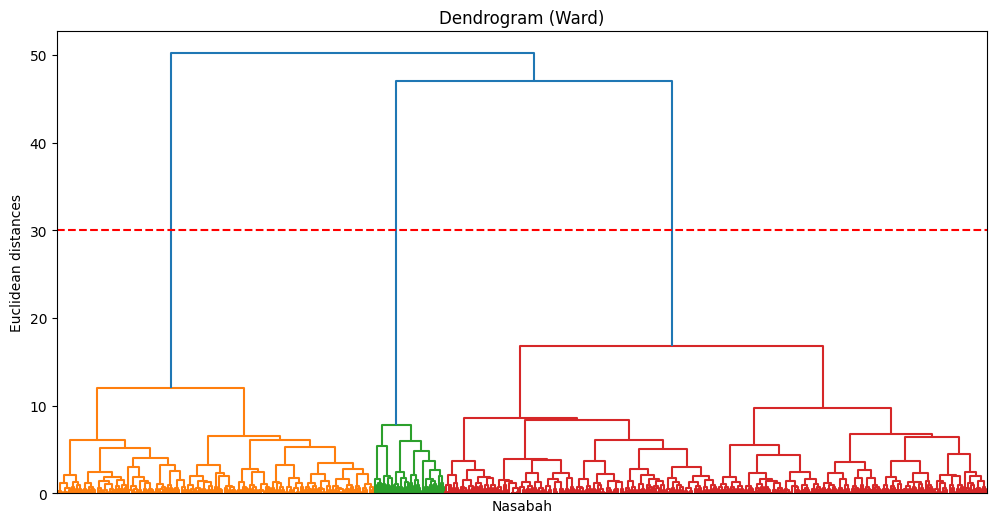

In [ ]:
# Dendrogram untuk menentukan jumlah cluster
plt.figure(figsize=(12, 6))
dendrogram = sch.dendrogram(sch.linkage(X_scaled, method='ward'), no_labels=True)
plt.axhline(y=30, color='red', linestyle='--')
plt.title('Dendrogram (Ward)')
plt.xlabel('Nasabah')
plt.ylabel('Euclidean distances')
plt.show()

Pada dendrogram terlihat tiga cabang besar yang baru bergabung pada jarak sangat tinggi (±47–50), sedangkan penggabungan di bawahnya terjadi pada jarak yang jauh lebih kecil (≤ ±17). Jika dendrogram dipotong pada garis merah (jarak ±30), terbentuk **3 cluster**, sehingga model dibuat dengan `n_clusters = 3`.

In [ ]:
# Model Agglomerative Clustering
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X_scaled)
df['Cluster'] = y_hc

print(df['Cluster'].value_counts().sort_index())
df.groupby('Cluster')[fitur].mean().round(2)

Cluster
0    385
1    225
2     50
Name: count, dtype: int64


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
Cluster,,,,,
0,33851.95,5.52,3.49,0.98,1.99
1,12151.11,2.42,0.94,3.55,6.86
2,141040.00,8.74,0.60,10.90,1.08


### Soal 2 - Scatterplot `Avg_Credit_Limit` vs `Total_Credit_Cards` Berdasarkan Cluster

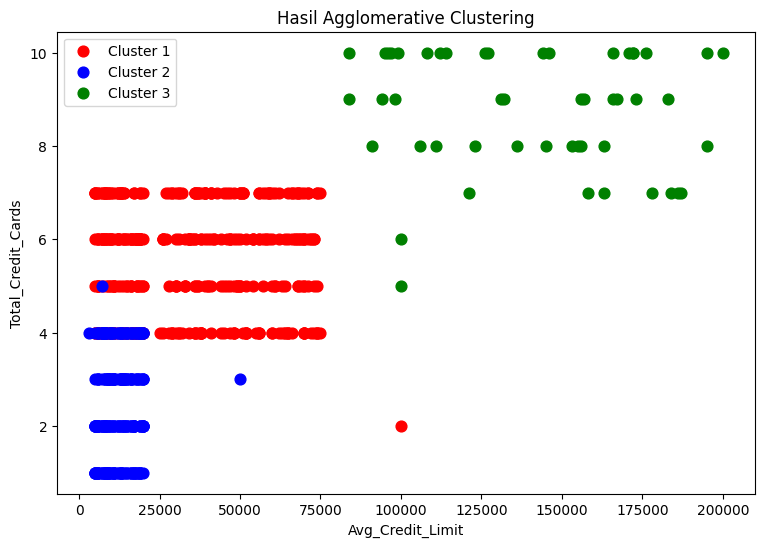

In [ ]:
warna = ['red', 'blue', 'green']
plt.figure(figsize=(9, 6))
for i in range(3):
    plt.scatter(df.loc[y_hc == i, 'Avg_Credit_Limit'],
                df.loc[y_hc == i, 'Total_Credit_Cards'],
                s=60, c=warna[i], label=f'Cluster {i+1}')
plt.title('Hasil Agglomerative Clustering')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.legend()
plt.show()

**Bentuk cluster berdasarkan dua fitur tersebut:**
- **Limit rendah, kartu sedikit** (±225 nasabah): limit rata-rata ±12.000 (maks. 50.000) dengan rata-rata ±2,4 kartu. Kelompok ini paling sering menelepon bank (rata-rata ±7 kali).
- **Limit menengah, kartu sedang** (±385 nasabah): limit rata-rata ±34.000 dengan rata-rata ±5,5 kartu. Kelompok ini paling sering datang langsung ke bank (rata-rata ±3,5 kali).
- **Limit sangat tinggi, kartu banyak** (±50 nasabah): limit rata-rata ±141.000 (84.000–200.000) dengan rata-rata ±8,7 kartu. Kelompok ini terpisah jauh di kanan atas dan paling aktif bertransaksi online (rata-rata ±11 kali).

Kedua cluster pertama bertumpuk pada rentang limit yang mirip, karena pembedanya sebagian besar dari jumlah kartu dan pola interaksi (kunjungan bank, telepon, online) yang tidak tampak pada dua sumbu ini. Cluster nasabah premium terlihat jelas terpisah.

### Soal 3 - Silhouette Score dan Davies-Bouldin Index (DBI)

In [ ]:
sil = silhouette_score(X_scaled, y_hc)
dbi = davies_bouldin_score(X_scaled, y_hc)

print(f'Silhouette Score    : {sil}')
print(f'Davies-Bouldin Index: {dbi}')

Silhouette Score    : 0.5147639589977819
Davies-Bouldin Index: 0.680959518994733


**Analisis:**
- **Silhouette score ±0,52** termasuk cukup baik (rentang -1 s.d. 1). Sebagian besar nasabah lebih dekat ke anggota cluster-nya sendiri daripada ke cluster lain.
- **DBI ±0,68** tergolong rendah (semakin kecil semakin baik), artinya ketiga cluster cukup padat dan terpisah satu sama lain.

Dibandingkan model DBSCAN pada JS07 (silhouette ±0,52, DBI ±1,76), Agglomerative Clustering dengan 3 cluster menghasilkan separasi yang lebih baik (DBI jauh lebih kecil) dan tidak menghasilkan noise.